# Quiz 3：Vision Transformer（35 分）

**蘇芯儀 / Sharon0726**

ViT 微調與推論（20）、ResNet 微調與推論（10）、Macro-AUC 比較（5）。

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
R=Path('results')
assert R.exists(), 'Run from Week4; results/ is required.'
def read(name): return json.loads((R/name).read_text(encoding='utf-8'))
def show(name): display(Image(filename=str(R/'figures'/name)))


## 微調設計

ViT-Tiny 更新最後 Transformer block、LayerNorm、head；ResNet18 更新 layer4 與 fc。其餘層凍結。相同 train/val/test、6 epochs、AdamW lr=0.0003，以 validation accuracy 選 checkpoint。ViT 預訓練使用 ImageNet-21k + 1k，ResNet 使用 ImageNet-1k，這是比較限制。

In [2]:
source=Path('models.py').read_text(encoding='utf-8')
display(Markdown('```python\n'+source[source.index('def make_vision'):]+'```'))

```python
def make_vision(kind, pretrained=True):
    import timm
    from torchvision.models import ResNet18_Weights, resnet18
    if kind == 'vit':
        model = timm.create_model('vit_tiny_patch16_224.augreg_in21k_ft_in1k', pretrained=pretrained, num_classes=10)
        train_prefixes = ('blocks.11.', 'norm.', 'head.')
    else:
        model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1 if pretrained else None)
        model.fc = nn.Linear(model.fc.in_features, 10)
        train_prefixes = ('layer4.', 'fc.')
    for name, p in model.named_parameters():
        p.requires_grad = name.startswith(train_prefixes)
    return model


def vision_train_mode(model, kind):
    model.eval()  # Frozen stages (including BN statistics) stay fixed.
    if kind == 'vit':
        model.blocks[-1].train()
        model.norm.train()
        model.head.train()
    else:
        model.layer4.train()
        model.fc.train()
```

,model,best_epoch,train_seconds,total_parameters,trainable_parameters,backbone_probe,backbone_max_abs_change,accuracy,macro_f1,macro_precision,macro_recall,auc
0,vit,3,150.274203,5526346,447178,blocks.11.attn.qkv.weight,0.041054,0.9260,0.926012,0.926664,0.9260,0.996741
1,resnet,5,148.513189,11181642,8398858,layer4.0.conv1.weight,0.036770,0.8949,0.894902,0.899449,0.8949,0.993210


PASS: both pretrained backbones were updated.


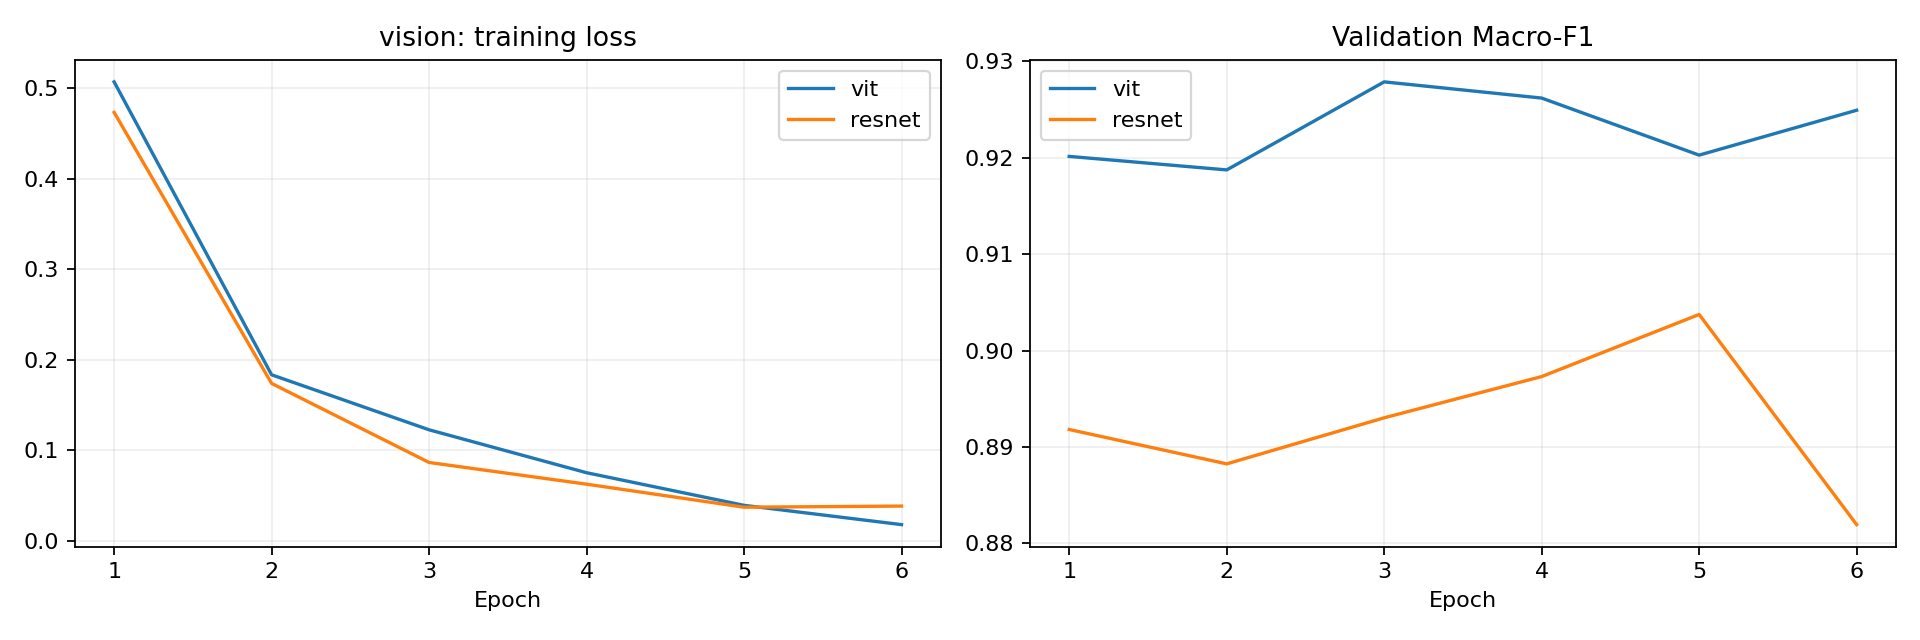

In [3]:
m=pd.read_csv(R/'vision_metrics.csv'); display(m)
assert (m.backbone_max_abs_change>0).all()
print('PASS: both pretrained backbones were updated.')
show('vision_learning.png')

重新微調入口：`python quiz3_vision.py`。需要 GPU 時使用同目錄 Colab Runner；預設不在這份結果閱讀版 Notebook 自動重訓。

## 完整 test 推論與 Macro-AUC

十類各自視為 positive 做 one-vs-rest ROC，再對十個 AUC 等權平均。測試包含全部 10,000 張，兩模型完全相同的 ID。

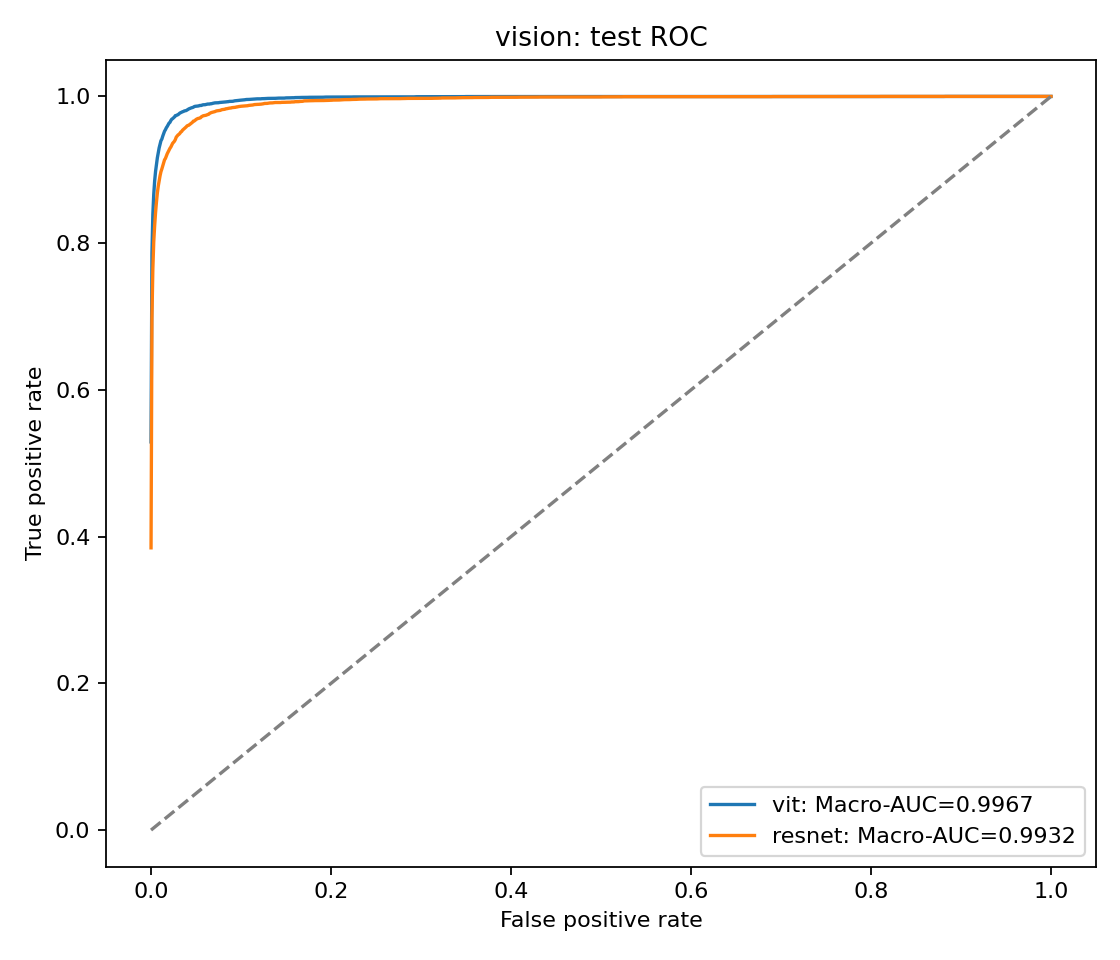

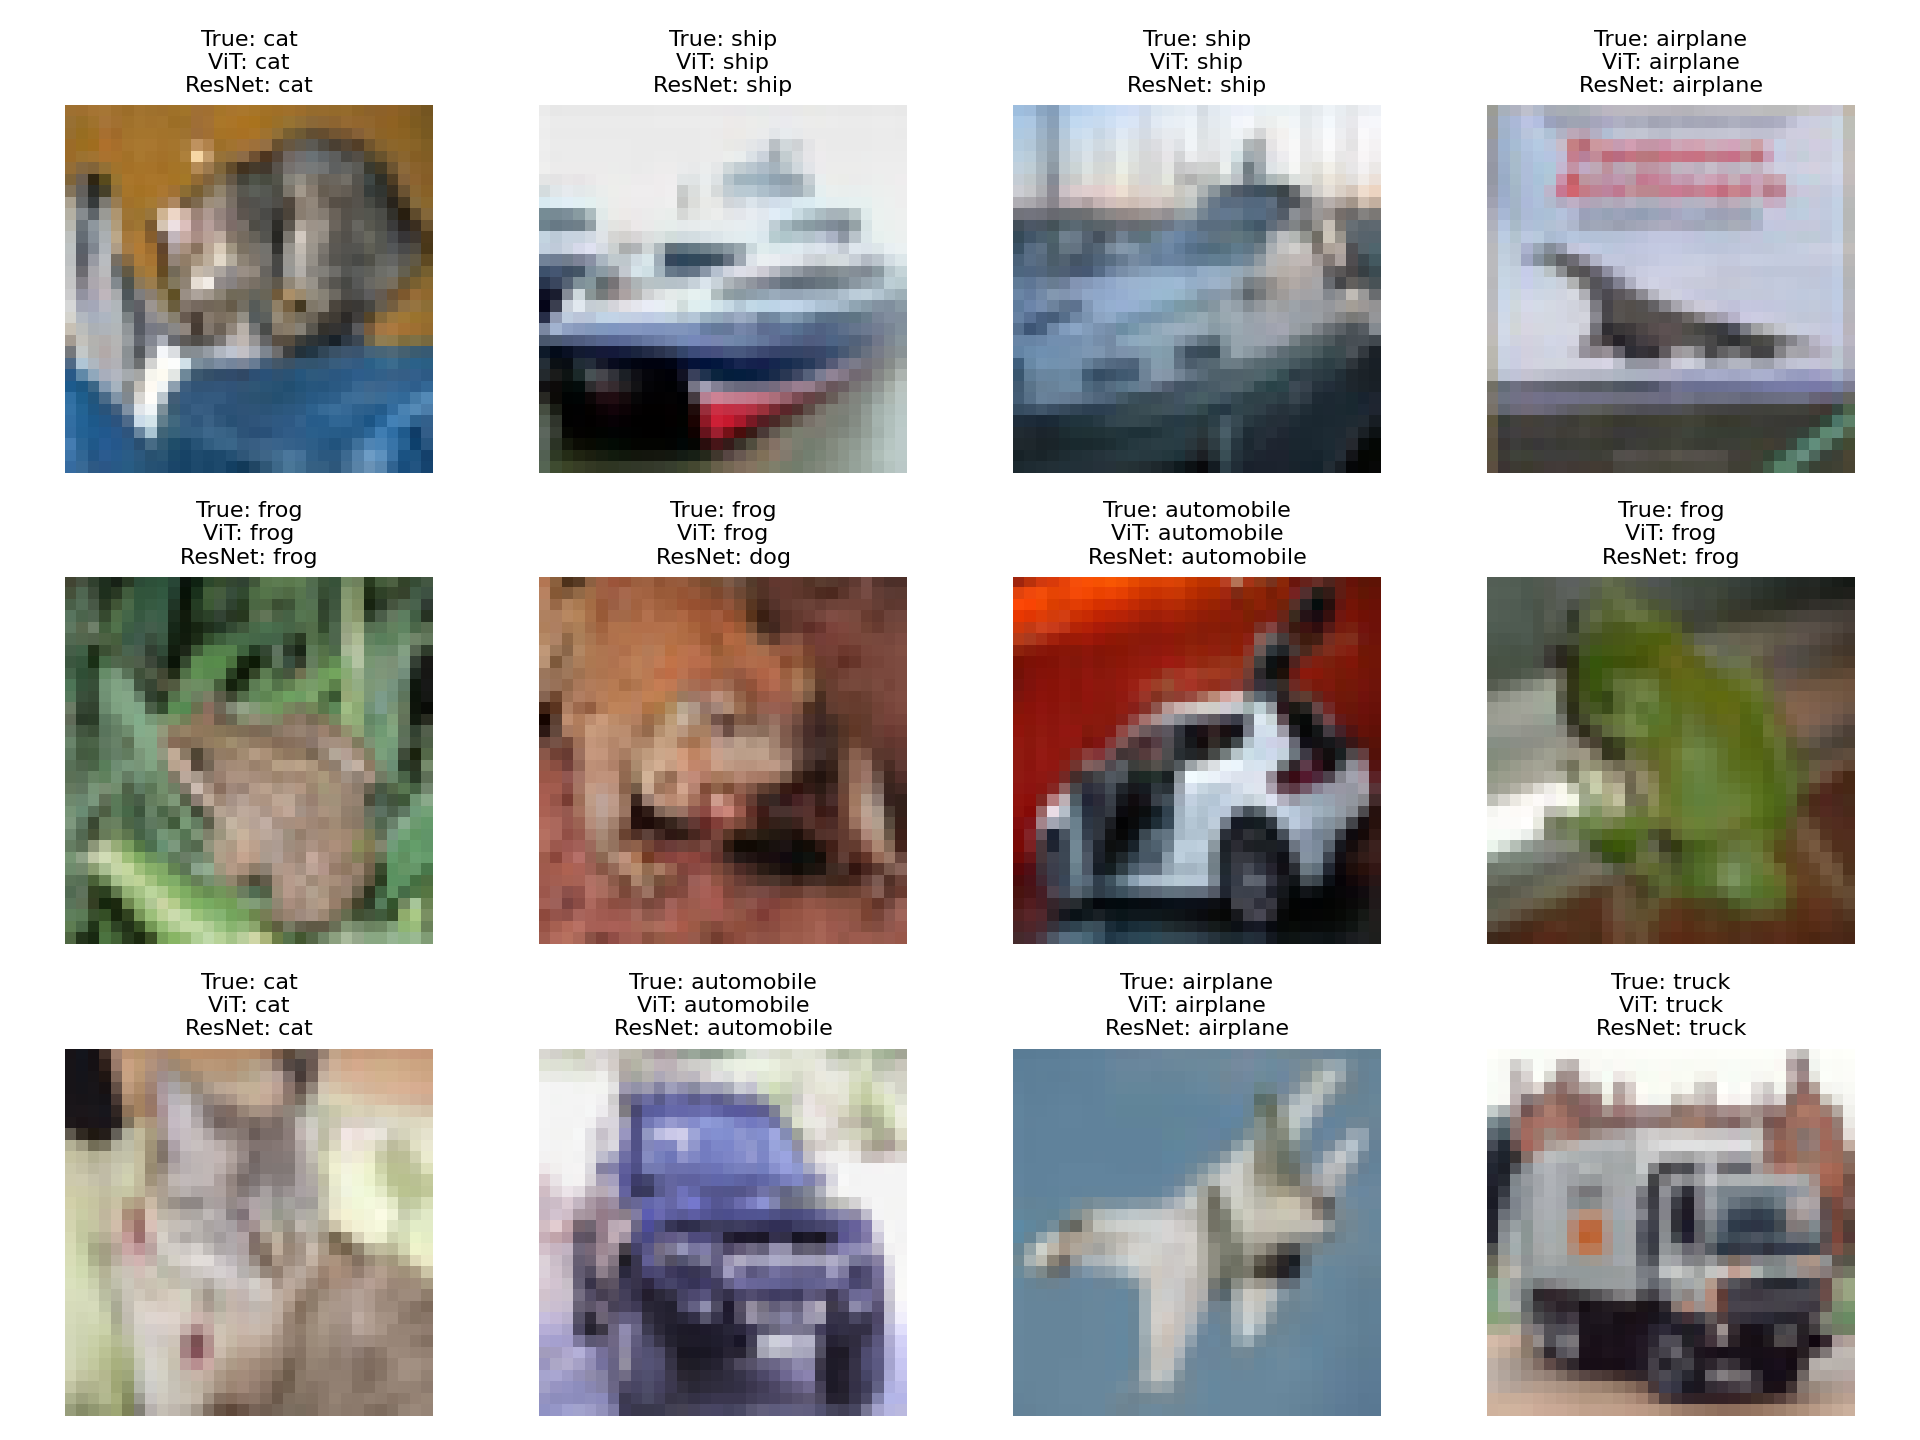

vit


,id,true,predicted,p_0,p_1,p_2,p_3,p_4,p_5,p_6,p_7,p_8,p_9
0,0,3,3,3.119226e-06,0.000002,0.000022,0.999809,9.768730e-06,0.000110,0.000018,2.010294e-05,0.000002,0.000005
1,1,8,8,3.836654e-04,0.000092,0.000006,0.000001,1.279535e-07,0.000002,0.000004,5.335488e-06,0.999495,0.000011
2,2,8,8,6.009140e-04,0.002189,0.000017,0.000028,2.455798e-06,0.000004,0.000008,1.081860e-04,0.997008,0.000034
3,3,0,0,8.389010e-01,0.000382,0.140194,0.013271,2.542417e-04,0.000088,0.002036,1.776893e-03,0.002872,0.000223
4,4,6,6,3.372170e-07,0.000028,0.000104,0.000016,3.973388e-07,0.000014,0.999805,7.718975e-07,0.000008,0.000025


resnet


,id,true,predicted,p_0,p_1,p_2,p_3,p_4,p_5,p_6,p_7,p_8,p_9
0,0,3,3,1.876448e-05,0.000012,3.390029e-04,9.818560e-01,3.298722e-07,1.763549e-02,1.136349e-04,1.050538e-05,6.383339e-07,1.330601e-05
1,1,8,8,1.641038e-04,0.000002,1.333557e-07,3.355838e-07,2.057094e-08,1.652922e-08,6.153356e-08,1.050818e-07,9.998325e-01,1.044679e-07
2,2,8,8,8.333029e-07,0.001768,5.897472e-07,2.046089e-07,9.312949e-08,3.748662e-07,2.536471e-07,8.648072e-07,9.982267e-01,1.696521e-06
3,3,0,0,9.905278e-01,0.000004,8.387593e-03,3.672676e-04,4.749058e-06,1.143528e-06,2.695785e-05,2.775517e-06,6.342718e-04,4.388528e-05
4,4,6,6,3.281348e-08,0.000001,2.171606e-06,1.057165e-07,4.429153e-07,5.142160e-08,9.999956e-01,6.299365e-09,5.132127e-08,3.452798e-07


In [4]:
show('vision_roc.png')
show('vision_examples.png')
for model in ['vit','resnet']:
    print(model)
    display(pd.read_csv(R/f'predictions/vision_{model}.csv').head(5))

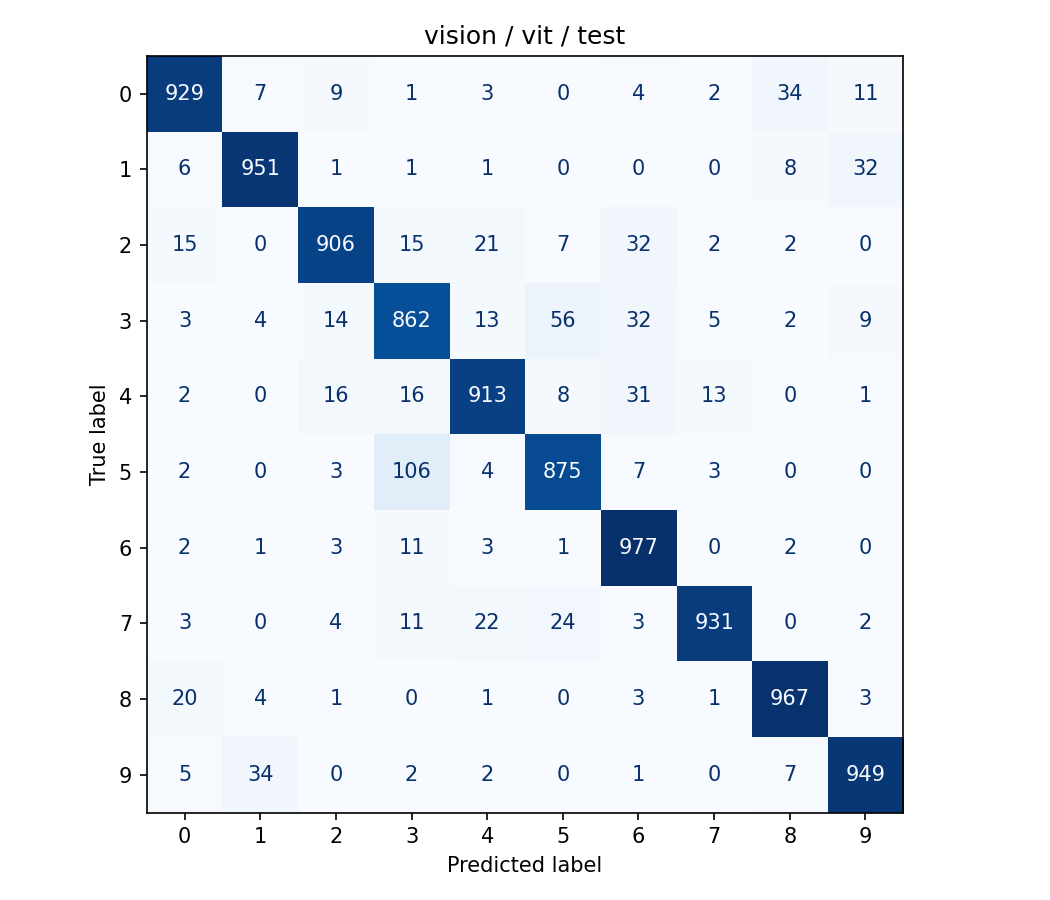

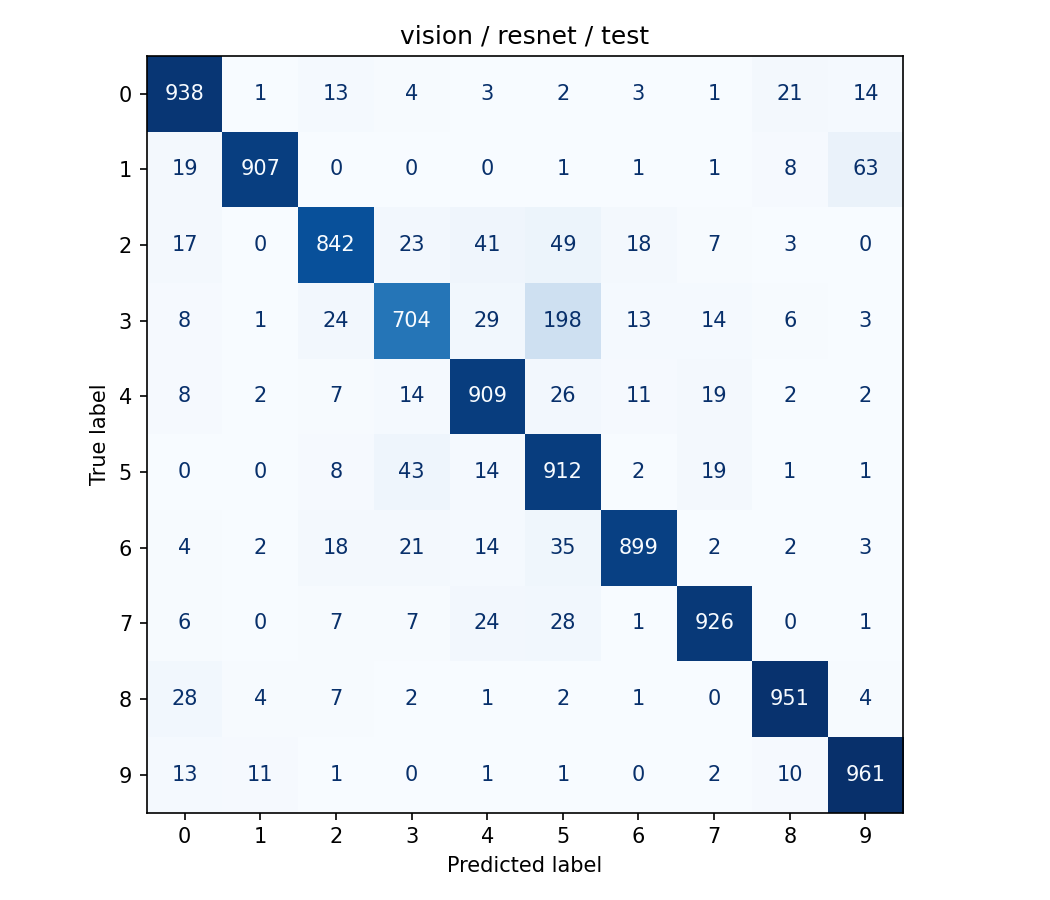

In [5]:
show('vision_vit_confusion.png')
show('vision_resnet_confusion.png')